# Simple Linear Regression Practice

In this notebook, we will use **one feature** to predict a numeric target with linear regression. The dataset is the built-in diabetes dataset from scikit-learn, so no download is needed.

The goal is to practice the full workflow: inspect the data, split it, fit a model, evaluate it, and interpret predictions. The target is a quantitative measure of disease progression one year after baseline; this is a learning exercise, not a medical tool.

## Learning goals
- Distinguish features (`X`) from the target (`y`).
- Train and evaluate a simple linear regression model.
- Interpret MAE, RMSE, and R-squared.
- Compare the model with a simple baseline.

Run the cells from top to bottom. Try the practice tasks before reading their solutions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

## 1. Load and explore the data

`load_diabetes(as_frame=True)` returns a pandas DataFrame. The feature columns are standardized, so values such as BMI are not in their original measurement units.

In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")
display(df.head())
print("\nTarget:", diabetes.target.name)
print("Features:", diabetes.feature_names)

Rows: 442, columns: 11


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Target: target
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


For this first model, use only `bmi` to predict `target`. This keeps the model easy to visualize and interpret. The target is a disease-progression measure, not a diagnosis.

In [3]:
X = df[["bmi"]]  # Keep X two-dimensional for scikit-learn
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values in X:", X.isna().sum().sum())

X shape: (442, 1)
y shape: (442,)
Missing values in X: 0


### Quick exploration

Before fitting a model, plot the feature against the target. Does the relationship look perfectly linear? What else do you notice?

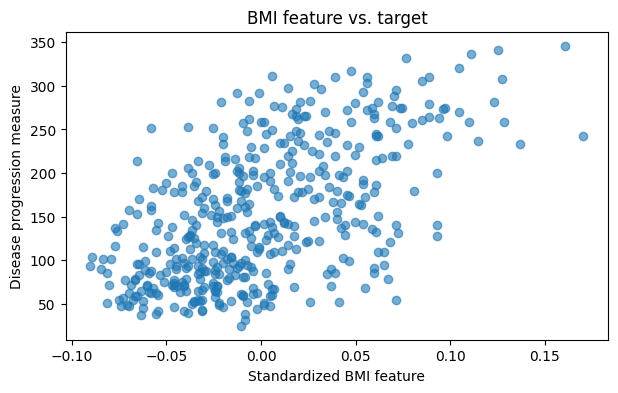

In [4]:
plt.figure(figsize=(7, 4))
plt.scatter(X["bmi"], y, alpha=0.6)
plt.xlabel("Standardized BMI feature")
plt.ylabel("Disease progression measure")
plt.title("BMI feature vs. target")
plt.show()

## 2. Split into training and test sets

The model learns from the training set. We reserve the test set for evaluation on data it did not train on. A fixed `random_state` makes the split reproducible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 353
Test rows: 89


## 3. Train a linear regression model

The model has the form `prediction = intercept + coefficient * bmi`. Fit it using the training data, then inspect its parameters.

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 2))
print("BMI coefficient:", round(model.coef_[0], 2))

Intercept: 152.0
BMI coefficient: 998.58


**Interpretation prompt:** Given this dataset's standardized BMI feature, describe what the coefficient says about the model's prediction when BMI increases by one feature unit. This is an association in this dataset, not evidence that BMI causes the change.

## 4. Evaluate on the test set

- **MAE** is the average absolute prediction error, in target units.
- **RMSE** is also in target units and penalizes larger errors more strongly.
- **R-squared** compares the model with predicting the test-set mean; it can be negative when the model performs worse than that baseline.

In [7]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R^2:  {r2:.3f}")

MAE:  52.26
RMSE: 63.73
R^2:  0.233


### Visualize predictions

The line below is the fitted model over the test points. The vertical distance between a point and the line is its prediction error (residual).

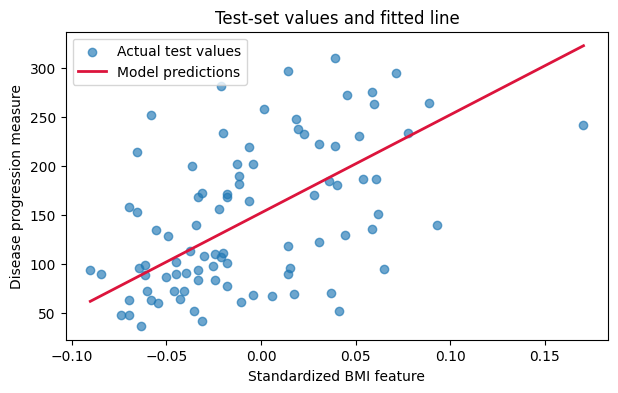

In [8]:
order = np.argsort(X_test["bmi"].to_numpy())
x_sorted = X_test["bmi"].to_numpy()[order]
y_sorted = y_pred[order]

plt.figure(figsize=(7, 4))
plt.scatter(X_test["bmi"], y_test, alpha=0.65, label="Actual test values")
plt.plot(x_sorted, y_sorted, color="crimson", linewidth=2, label="Model predictions")
plt.xlabel("Standardized BMI feature")
plt.ylabel("Disease progression measure")
plt.title("Test-set values and fitted line")
plt.legend()
plt.show()

## 5. Compare against a baseline

A model is useful only if it improves on a simple alternative. `DummyRegressor` always predicts the training-set mean. Compare both models using the same test data and metric.

In [9]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(f"Linear regression MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"Mean baseline MAE:     {mean_absolute_error(y_test, baseline_pred):.2f}")

Linear regression MAE: 52.26
Mean baseline MAE:     64.01


## 6. Make a prediction

Pass a two-dimensional input with the same feature name and structure as the training data. The example uses a BMI feature value observed in the dataset.

In [10]:
example_bmi = X.iloc[[0]]
example_prediction = model.predict(example_bmi)[0]

print("Input BMI feature value:", round(example_bmi.iloc[0, 0], 3))
print("Predicted target:", round(example_prediction, 1))

Input BMI feature value: 0.062
Predicted target: 213.6


## Practice tasks

Try these before looking at the solution cell:
1. Change the single feature from `bmi` to `bp` (blood pressure) and rerun the split, fit, and evaluation steps. How do the test MAE and R-squared change?
2. Change `test_size` to `0.3`. Why might the reported test metrics change even though the model type is unchanged?
3. Add a second feature, `s5`, to `X`. Does using two features improve the test MAE over using BMI alone?

### Optional solution: compare BMI with two features

This keeps the same train/test rows so the comparison is fair. Run it after completing the tasks.

In [11]:
X_two = df[["bmi", "s5"]]
X_two_train, X_two_test, y_two_train, y_two_test = train_test_split(
    X_two, y, test_size=0.2, random_state=42
)

two_feature_model = LinearRegression().fit(X_two_train, y_two_train)
two_feature_pred = two_feature_model.predict(X_two_test)

print(f"BMI only MAE:       {mean_absolute_error(y_test, y_pred):.2f}")
print(f"BMI and s5 MAE:     {mean_absolute_error(y_two_test, two_feature_pred):.2f}")
print(f"BMI only R^2:       {r2_score(y_test, y_pred):.3f}")
print(f"BMI and s5 R^2:     {r2_score(y_two_test, two_feature_pred):.3f}")

BMI only MAE:       52.26
BMI and s5 MAE:     43.99
BMI only R^2:       0.233
BMI and s5 R^2:     0.452


## Key takeaways

- A regression model predicts a numeric value; always separate training data from test data when evaluating it.
- No single metric tells the whole story. Interpret error metrics in the target's units and compare against a baseline.
- A simple one-feature model is useful for learning, but it does not capture every factor and should not be used to make health decisions.
- Model performance on this small dataset is only an estimate; results can vary with the split and chosen features.